# Use Case 4: Reporting from MySQL

This notebook stores, queries and presents results straight from MySQL.

```
 chicago_crime (fact)  ──►  summary tables  ──►  SQL queries  ──►  views  ──►  pd.read_sql  ──►  charts
   (loaded in UC1)          (mysql-connector)                     vw_crime_yearly
                                                                  vw_crime_by_category
```

All the numbers here come from MySQL, not from the pickle file. The assignment asks for the Python MySQL Connector (`mysql-connector-python`) to create and load tables, so that's what I use.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

import crime_utils as cu

cu.set_style()

## Connecting with mysql-connector
The login details are read from `.env` (see the README). Passwords shouldn't be written into a notebook.

In [2]:
cnx = cu.get_mysql_connection()
cur = cnx.cursor()
cur.execute("SELECT VERSION(), DATABASE(), (SELECT COUNT(*) FROM chicago_crime)")
version, db, n = cur.fetchone()
print(f"Connected to MySQL {version} | database = {db} | chicago_crime rows = {n:,}")

Connected to MySQL 8.4.7 | database = chicago_crime_db | chicago_crime rows = 498


## 1. Create and fill the summary tables

Summary tables hold results that are already calculated, so a report doesn't have to scan the whole fact table each time. I make two:

| Table | One row per | Columns |
|---|---|---|
| `summary_crime_yearly` | year | total crimes, arrests, arrest rate, domestic crimes |
| `summary_crime_category` | crime type | total, % of all crimes, arrests, arrest rate |

How this works with mysql-connector:
* `cursor.execute(sql)` runs a single statement.
* `INSERT ... SELECT` does the aggregation inside MySQL and inserts the result in one go.
* `cnx.commit()` saves the changes. mysql-connector doesn't auto-commit by default.

In [3]:
DDL = {
    "summary_crime_yearly": """
        CREATE TABLE summary_crime_yearly (
            year            SMALLINT     NOT NULL PRIMARY KEY,
            total_crimes    INT          NOT NULL,
            total_arrests   INT          NOT NULL,
            arrest_rate_pct DECIMAL(5,2) NOT NULL,
            domestic_crimes INT          NOT NULL)""",
    "summary_crime_category": """
        CREATE TABLE summary_crime_category (
            primary_type    VARCHAR(64)  NOT NULL PRIMARY KEY,
            total_crimes    INT          NOT NULL,
            pct_of_total    DECIMAL(5,2) NOT NULL,
            total_arrests   INT          NOT NULL,
            arrest_rate_pct DECIMAL(5,2) NOT NULL)""",
}

LOAD = {
    "summary_crime_yearly": """
        INSERT INTO summary_crime_yearly
        SELECT year, COUNT(*), SUM(arrest), ROUND(100 * AVG(arrest), 2), SUM(domestic)
        FROM chicago_crime GROUP BY year""",
    "summary_crime_category": """
        INSERT INTO summary_crime_category
        SELECT i.primary_type, COUNT(*),
               ROUND(100 * COUNT(*) / (SELECT COUNT(*) FROM chicago_crime), 2),
               SUM(c.arrest), ROUND(100 * AVG(c.arrest), 2)
        FROM chicago_crime c JOIN iucr i ON i.iucr_code = c.iucr_code
        GROUP BY i.primary_type""",
}

try:
    for table in DDL:
        cur.execute(f"DROP TABLE IF EXISTS {table}")
        cur.execute(DDL[table])
        cur.execute(LOAD[table])
        print(f"{table:<24} created and loaded: {cur.rowcount:>3} rows")
    cnx.commit()
except Exception:
    # this only undoes uncommitted INSERTs. DROP/CREATE TABLE commit automatically in MySQL,
    # so a failure might leave a table dropped or empty. Just fix the problem and run this cell again
    cnx.rollback()
    raise

summary_crime_yearly     created and loaded:   5 rows
summary_crime_category   created and loaded:  23 rows


A small helper that runs a query with mysql-connector and returns a DataFrame (the column names come from `cursor.description`).

In [4]:
def query_df(sql, params=None):
    c = cnx.cursor()
    c.execute(sql, params or ())
    out = pd.DataFrame(c.fetchall(), columns=[d[0] for d in c.description])
    c.close()
    return out

display(query_df("SELECT * FROM summary_crime_yearly ORDER BY year"))
display(query_df("SELECT * FROM summary_crime_category ORDER BY total_crimes DESC"))

,year,total_crimes,total_arrests,arrest_rate_pct,domestic_crimes
0,2012,2,2,100.00,0
1,2013,1,1,100.00,0
2,2014,1,0,0.00,0
3,2015,4,2,50.00,1
4,2016,490,119,24.29,67


,primary_type,total_crimes,pct_of_total,total_arrests,arrest_rate_pct
0,THEFT,105,21.08,10,9.52
1,BATTERY,85,17.07,20,23.53
2,CRIMINAL DAMAGE,49,9.84,2,4.08
3,OTHER OFFENSE,39,7.83,8,20.51
4,DECEPTIVE PRACTICE,38,7.63,5,13.16
5,ASSAULT,35,7.03,10,28.57
6,NARCOTICS,32,6.43,32,100.00
7,ROBBERY,30,6.02,6,20.00
8,CRIMINAL TRESPASS,17,3.41,15,88.24
9,MOTOR VEHICLE THEFT,16,3.21,0,0.00


## 2. MySQL queries
### 2a. Crimes per year

In [5]:
q_year = """
SELECT year, COUNT(*) AS crime_count
FROM chicago_crime
GROUP BY year
ORDER BY year"""
display(query_df(q_year))

,year,crime_count
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490


### 2b. Top 5 crime types and their share
`SUM(COUNT(*)) OVER ()` is a window function. It adds up the counts across all groups to get the overall total, but keeps each row, so every row can be divided by that total. It runs before `LIMIT`, which means the percentage is out of all crimes and not just the top 5.

In [6]:
q_top5 = """
SELECT i.primary_type,
       COUNT(*)                                         AS crime_count,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total
FROM chicago_crime c
JOIN iucr i ON i.iucr_code = c.iucr_code
GROUP BY i.primary_type
ORDER BY crime_count DESC
LIMIT 5"""
top5 = query_df(q_top5)
display(top5)
print(f"Top 5 together = {top5['pct_of_total'].astype(float).sum():.2f}% of all crimes")

,primary_type,crime_count,pct_of_total
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63


Top 5 together = 63.45% of all crimes


### 2c. Arrests per year
`arrest` is stored as 0 or 1, so `SUM(arrest)` gives the number of arrests and `AVG(arrest)` gives the arrest rate.

In [7]:
q_arrest = """
SELECT year,
       SUM(arrest)                 AS arrest_count,
       COUNT(*)                    AS crime_count,
       ROUND(100 * AVG(arrest), 2) AS arrest_rate_pct
FROM chicago_crime
GROUP BY year
ORDER BY year"""
display(query_df(q_arrest))

,year,arrest_count,crime_count,arrest_rate_pct
0,2012,2,2,100.00
1,2013,1,1,100.00
2,2014,0,1,0.00
3,2015,2,4,50.00
4,2016,119,490,24.29


## 3. Views
A view is a saved query that you can use like a table. It doesn't store any data itself; it runs the query each time you read from it, so it's always current. Using `CREATE OR REPLACE` means the script can be run more than once without errors.

In [8]:
VIEWS = {
    "vw_crime_yearly": """
        CREATE OR REPLACE VIEW vw_crime_yearly AS
        SELECT year,
               COUNT(*)                    AS total_crimes,
               SUM(arrest)                 AS total_arrests,
               ROUND(100 * AVG(arrest), 2) AS arrest_rate_pct,
               SUM(domestic)               AS domestic_crimes
        FROM chicago_crime
        GROUP BY year""",
    "vw_crime_by_category": """
        CREATE OR REPLACE VIEW vw_crime_by_category AS
        SELECT i.primary_type,
               COUNT(*)                                         AS total_crimes,
               ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total,
               SUM(c.arrest)                                    AS total_arrests,
               ROUND(100 * AVG(c.arrest), 2)                    AS arrest_rate_pct
        FROM chicago_crime c
        JOIN iucr i ON i.iucr_code = c.iucr_code
        GROUP BY i.primary_type""",
}
for name, ddl in VIEWS.items():
    cur.execute(ddl)
    print(f"View {name} created")
cnx.commit()

View vw_crime_yearly created
View vw_crime_by_category created


## 4. Reading the views into Pandas

The assignment uses `pd.read_sql("SELECT * FROM vw_crime_yearly", conn)`. Pandas officially supports SQLAlchemy connections (a raw mysql-connector connection works too, but it prints a warning), so here `conn` is a SQLAlchemy connection.

In [9]:
from sqlalchemy import text

engine = cu.get_engine()
with engine.connect() as conn:
    yearly = pd.read_sql(text("SELECT * FROM vw_crime_yearly ORDER BY year"), conn)
    by_cat = pd.read_sql(text("SELECT * FROM vw_crime_by_category ORDER BY total_crimes DESC"), conn)

# DECIMAL and SUM() results from MySQL can come back as Decimal objects or floats like 2.0, so convert them to normal numbers
for frame in (yearly, by_cat):
    for c in frame.columns:
        if c == "primary_type":
            continue
        frame[c] = pd.to_numeric(frame[c])
        if frame[c].notna().all() and (frame[c] % 1 == 0).all():   # whole numbers -> int
            frame[c] = frame[c].astype(int)

display(yearly)
display(by_cat.head(10))

,year,total_crimes,total_arrests,arrest_rate_pct,domestic_crimes
0,2012,2,2,100.00,0
1,2013,1,1,100.00,0
2,2014,1,0,0.00,0
3,2015,4,2,50.00,1
4,2016,490,119,24.29,67


,primary_type,total_crimes,pct_of_total,total_arrests,arrest_rate_pct
0,THEFT,105,21.08,10,9.52
1,BATTERY,85,17.07,20,23.53
2,CRIMINAL DAMAGE,49,9.84,2,4.08
3,OTHER OFFENSE,39,7.83,8,20.51
4,DECEPTIVE PRACTICE,38,7.63,5,13.16
5,ASSAULT,35,7.03,10,28.57
6,NARCOTICS,32,6.43,32,100.00
7,ROBBERY,30,6.02,6,20.00
8,CRIMINAL TRESPASS,17,3.41,15,88.24
9,MOTOR VEHICLE THEFT,16,3.21,0,0.00


Further analysis in Pandas on the data pulled from MySQL: each category's share of all arrests.

In [10]:
by_cat["share_of_all_arrests_%"] = (by_cat["total_arrests"] / by_cat["total_arrests"].sum() * 100).round(1)
display(by_cat[["primary_type", "total_crimes", "pct_of_total", "arrest_rate_pct",
                "share_of_all_arrests_%"]].head(10))

,primary_type,total_crimes,pct_of_total,arrest_rate_pct,share_of_all_arrests_%
0,THEFT,105,21.08,9.52,8.1
1,BATTERY,85,17.07,23.53,16.1
2,CRIMINAL DAMAGE,49,9.84,4.08,1.6
3,OTHER OFFENSE,39,7.83,20.51,6.5
4,DECEPTIVE PRACTICE,38,7.63,13.16,4.0
5,ASSAULT,35,7.03,28.57,8.1
6,NARCOTICS,32,6.43,100.00,25.8
7,ROBBERY,30,6.02,20.00,4.8
8,CRIMINAL TRESPASS,17,3.41,88.24,12.1
9,MOTOR VEHICLE THEFT,16,3.21,0.00,0.0


## 5. Charts from the MySQL data

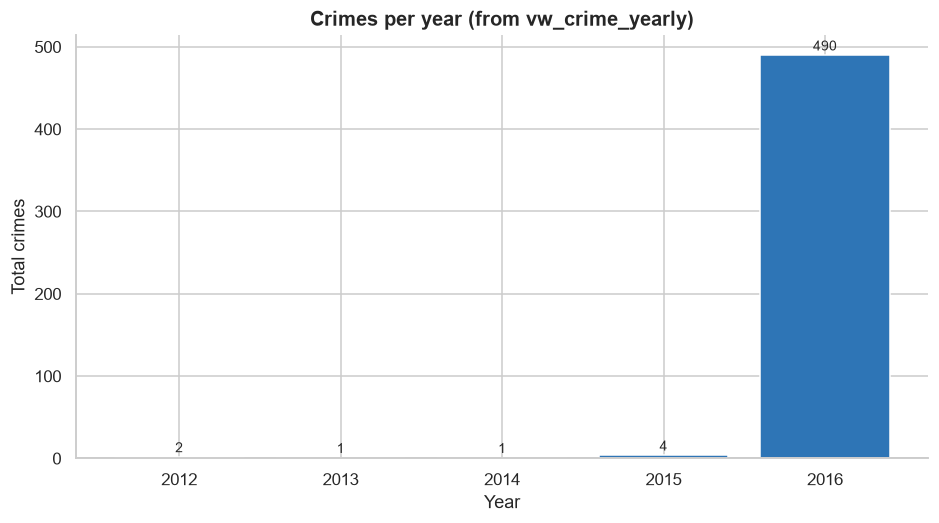

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(yearly["year"], yearly["total_crimes"], color="#2e75b6")
for x_, n_ in zip(yearly["year"], yearly["total_crimes"]):
    ax.annotate(f"{n_:,}", (x_, n_), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)
ax.set(xlabel="Year", ylabel="Total crimes", title="Crimes per year (from vw_crime_yearly)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xticks(yearly["year"])
cu.save_fig(fig, "uc4_01_yearly_from_mysql")
plt.show()

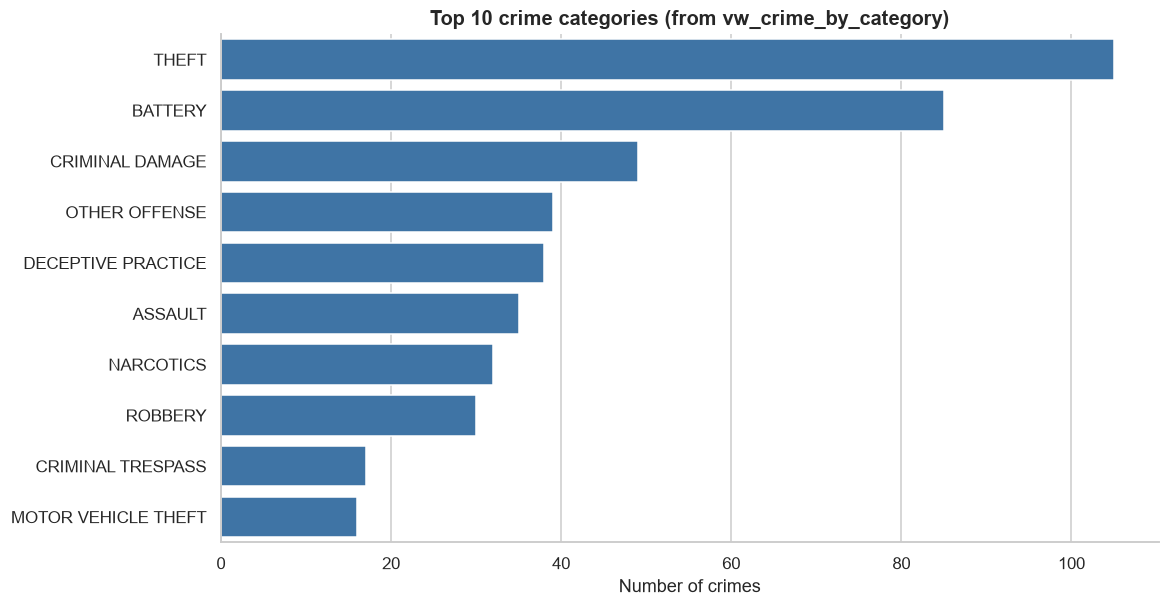

In [12]:
top = by_cat.head(10)
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=top, x="total_crimes", y="primary_type", ax=ax, color="#2e75b6")
ax.set(title="Top 10 crime categories (from vw_crime_by_category)", xlabel="Number of crimes", ylabel="")
cu.save_fig(fig, "uc4_02_categories_from_mysql")
plt.show()

## Closing the connections
It's good practice to close cursors and connections when you're done, since open connections take up server resources.

In [13]:
cur.close()
cnx.close()
engine.dispose()
print("Connections closed")

Connections closed
